In [ ]:
#determining survival days
X=np.zeros((160,12586))
Y=[]
check=[]
j=0
for i in range(198):
    if days[i]<=1500:
        X[j]=X[j]+X_all[i]
        Y.append('short')
        check.append(days[i])
        j=j+1
    if days[i]>=3000:
        X[j]=X[j]+X_all[i]
        Y.append('long')
        check.append(days[i])
        j=j+1
    

In [ ]:
var_filter1 = X1.var(0) >= np.percentile(X1.var(0), 30., method='nearest')
var_filter2 = X2.var(0) >= np.percentile(X2.var(0), 30., method='nearest')

In [ ]:
# mms = MinMaxScaler()
# X_norm = mms.fit_transform(X)
# #X_test_norm = mms.transform(X_test)

mms = MinMaxScaler()
X_train_norm = mms.fit_transform(X1[:, var_filter1])
X_test_norm = mms.fit_transform(X2[:, var_filter2])


Encode the classes

In [ ]:
le = LabelEncoder()
y_enc = le.fit_transform(Y1)
y_test_enc = le.transform(Y2)

le_mapping = dict(zip(le.transform(le.classes_), le.classes_))
num_classes = np.unique(y_enc).size

In [ ]:
var_filter_single= X_all.var(0) >= np.percentile(X_all.var(0), 30., method='nearest')
mms = MinMaxScaler()
X_train_norm = mms.fit_transform(X_all[:, var_filter_single])

le = LabelEncoder()
y_enc = le.fit_transform(Y)

le_mapping = dict(zip(le.transform(le.classes_), le.classes_))
num_classes = np.unique(y_enc).size
num_classes

2

In [ ]:
X_train_norm.shape

(162, 8810)

## DeepInsight Image Transformation
Convert data to image format using DeepInsight

In [ ]:
reducer = umap.UMAP(
    #n_neighbors=40,
    n_components=2,
    min_dist=0.5,
    metric='cosine',
    n_jobs=-1,
    ##random_state=42
)

pixel_size = (32,32)

it = ImageTransformer(
    feature_extractor='kPCA',
    pixels=pixel_size)


printing result from KernelPCA(kernel='rbf', n_components=2) and the xyz is  (8810, 2)
printing chvertices


/home/shelia/AllFiles/Research_tuly/pyDeepInsight/pyDeepInsight_SRT/examples/Scripts/pyDeepInsightv3/image_transformer.py:278: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(x_new[:, 0], x_new[:, 1], s=1,


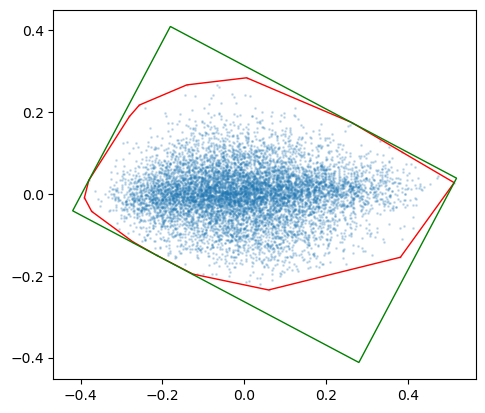

In [ ]:
it.fit(X_train_norm, y=Y, plot=True)

In [ ]:
##it.fit(X_norm, y=Y, plot=True)
from sklearn.decomposition import PCA, KernelPCA

kernel_pca = KernelPCA(
    n_components=2, kernel="rbf",gamma=.01)

X_train_kpca=kernel_pca.fit_transform(X_train_norm.transpose())
X_test_kpca = kernel_pca.fit(X_train_norm.transpose).transform(X_test_norm.transpose)

In [ ]:
ig, (kernel_pca_proj_train,kernel_pca_proj_test) = plt.subplots(
    ncols=2, figsize=(14, 4)
)

kernel_pca_proj_train.scatter(X_train_kpca[:, 0], X_train_kpca[:, 1],s=1,cmap=plt.cm.get_cmap("jet", 10), alpha=0.2)
kernel_pca_proj_train.set_ylabel("Principal component #1")
kernel_pca_proj_train.set_xlabel("Principal component #0")
kernel_pca_proj_train.set_title("Projection of training data\n using kPCA")


kernel_pca_proj_test.scatter(X_test_kpca[:, 0], X_test_kpca[:, 1],s=1,cmap=plt.cm.get_cmap("jet", 10), alpha=0.2)
kernel_pca_proj_test.set_ylabel("Principal component #1")
kernel_pca_proj_test.set_xlabel("Principal component #0")
kernel_pca_proj_test.set_title("Projection of testing data\n using kPCA")



In [ ]:
X_img = it.transform(X_norm)
#X_test_img = it.transform(X_test_norm)

In [ ]:
 it1 = ImageTransformer(
        feature_extractor=reducer,
        pixels=pixel_size)
    
    it2 = ImageTransformer(
        feature_extractor=reducer,
        pixels=pixel_size)
    
    it1.fit(X_train_norm, y=y_train, plot=False)
    it2.fit(X_test_norm, y=y_test, plot=False)

In [ ]:
import torch

# Check if CUDA is available
if torch.cuda.is_available():
    print("CUDA is available! GPU is being used.")
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
else:
    print("CUDA is not available. CPU is being used.")


keys,values = zip(*val.items())
max_val=(max(values))
key=next(key for key, value in val.items() if value==(max_val))
key,max_val